<a href="https://colab.research.google.com/github/Rashedrahmann/learnig-log/blob/Rashed/Image_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("phucthaiv02/butterfly-image-classification")

print("Path to dataset files:", path)

100%|██████████| 226M/226M [00:01<00:00, 214MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/phucthaiv02/butterfly-image-classification/versions/4


=== Dataset Validation ===
Train CSV rows: 6499 | Actual train images: 6499
Test CSV rows:  2786  | Actual test images:  2786
✔ Check Passed: Metadata sizes match actual file counts.
Missing train images: 0
Missing test images:  0

Loading random sample images to check reading integrity...


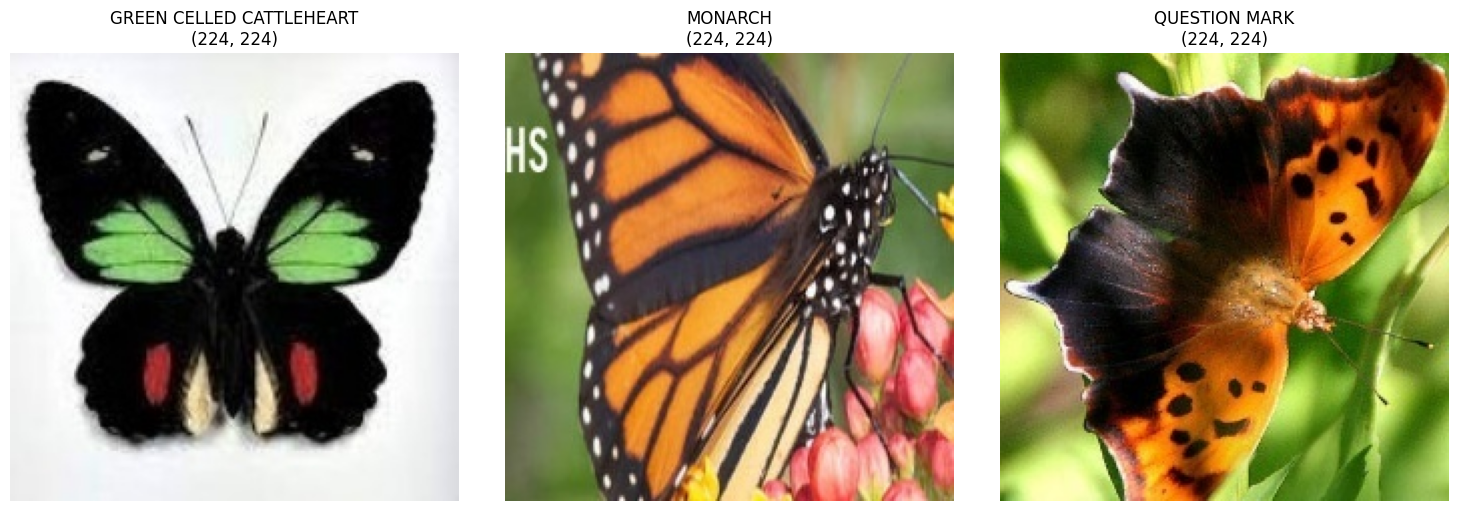

In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Define paths from the kagglehub dataset path
train_dir = os.path.join(path, 'train')
test_dir = os.path.join(path, 'test')
train_csv_path = os.path.join(path, 'Training_set.csv')
test_csv_path = os.path.join(path, 'Testing_set.csv')

# Load metadata DataFrames
train_df = pd.read_csv(train_csv_path)
test_df = pd.read_csv(test_csv_path)

# 1. Count actual images in directories
train_images = [f for f in os.listdir(train_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
test_images = [f for f in os.listdir(test_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

print("=== Dataset Validation ===")
print(f"Train CSV rows: {len(train_df)} | Actual train images: {len(train_images)}")
print(f"Test CSV rows:  {len(test_df)}  | Actual test images:  {len(test_images)}")

# Check if image counts perfectly match metadata entries
assert len(train_df) == len(train_images), "Mismatch in training set size!"
assert len(test_df) == len(test_images), "Mismatch in testing set size!"
print("✔ Check Passed: Metadata sizes match actual file counts.")

# 2. Check for missing or broken images
missing_train = [img for img in train_df['filename'] if img not in train_images]
missing_test = [img for img in test_df['filename'] if img not in test_images]
print(f"Missing train images: {len(missing_train)}")
print(f"Missing test images:  {len(missing_test)}")

# 3. Load and display sample images to verify integrity
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
print("\nLoading random sample images to check reading integrity...")
for i, idx in enumerate(train_df.sample(3, random_state=42).index):
    row = train_df.iloc[idx]
    img_path = os.path.join(train_dir, row['filename'])
    img = Image.open(img_path)
    axes[i].imshow(img)
    axes[i].set_title(f"{row['label']}\n{img.size}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

In [5]:
# 'path' comes from your kagglehub cell
for root, dirs, files in os.walk(path):
    depth = root.replace(path, "").count(os.sep)
    if depth <= 1:
        print(f"{'  ' * depth}{os.path.basename(root)}/  -> {len(dirs)} subdirs, {len(files)} files")

print("\n--- CSV files ---")
for f in os.listdir(path):
    if f.endswith(".csv"):
        df = pd.read_csv(os.path.join(path, f))
        print(f, df.shape)
        print(df.head(), "\n")

4/  -> 2 subdirs, 2 files
  train/  -> 0 subdirs, 6499 files
  test/  -> 0 subdirs, 2786 files

--- CSV files ---
Testing_set.csv (2786, 1)
      filename
0  Image_1.jpg
1  Image_2.jpg
2  Image_3.jpg
3  Image_4.jpg
4  Image_5.jpg 

Training_set.csv (6499, 2)
      filename                     label
0  Image_1.jpg          SOUTHERN DOGFACE
1  Image_2.jpg                    ADONIS
2  Image_3.jpg            BROWN SIPROETA
3  Image_4.jpg                   MONARCH
4  Image_5.jpg  GREEN CELLED CATTLEHEART 



In [9]:
df.info

<bound method DataFrame.info of             filename                     label
0        Image_1.jpg          SOUTHERN DOGFACE
1        Image_2.jpg                    ADONIS
2        Image_3.jpg            BROWN SIPROETA
3        Image_4.jpg                   MONARCH
4        Image_5.jpg  GREEN CELLED CATTLEHEART
...              ...                       ...
6494  Image_6495.jpg          MANGROVE SKIPPER
6495  Image_6496.jpg            MOURNING CLOAK
6496  Image_6497.jpg                   APPOLLO
6497  Image_6498.jpg           ELBOWED PIERROT
6498  Image_6499.jpg                     ATALA

[6499 rows x 2 columns]>

In [8]:
df.head(120)

,filename,label
0,Image_1.jpg,SOUTHERN DOGFACE
1,Image_2.jpg,ADONIS
2,Image_3.jpg,BROWN SIPROETA
3,Image_4.jpg,MONARCH
4,Image_5.jpg,GREEN CELLED CATTLEHEART
...,...,...
115,Image_116.jpg,CABBAGE WHITE
116,Image_117.jpg,AMERICAN SNOOT
117,Image_118.jpg,BECKERS WHITE
118,Image_119.jpg,CABBAGE WHITE


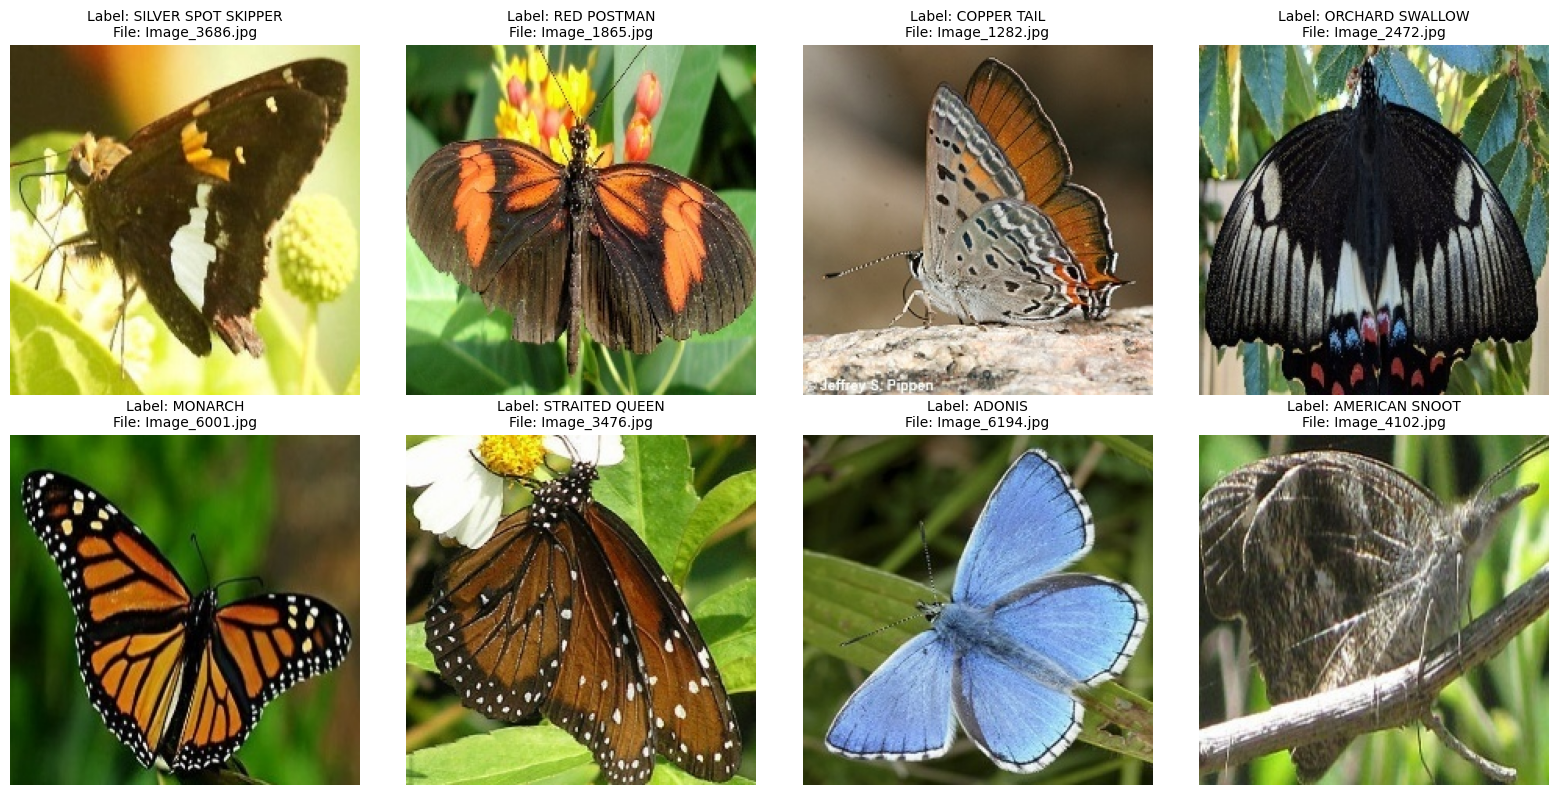

In [11]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Configure training paths
train_dir = os.path.join(path, 'train')
train_csv_path = os.path.join(path, 'Training_set.csv')
train_df = pd.read_csv(train_csv_path)

# Select 8 random samples to verify labels
sample_df = train_df.sample(8, random_state=12)

# Plot the grid
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for idx, (ax, (_, row)) in enumerate(zip(axes.flatten(), sample_df.iterrows())):
    img_path = os.path.join(train_dir, row['filename'])
    img = Image.open(img_path)
    ax.imshow(img)
    ax.set_title(f"Label: {row['label']}\nFile: {row['filename']}", fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [12]:
import os
import pandas as pd

# Define the paths
train_dir = os.path.join(path, 'train')
test_dir = os.path.join(path, 'test')

# Load original CSV files
train_csv = pd.read_csv(os.path.join(path, 'Training_set.csv'))
test_csv = pd.read_csv(os.path.join(path, 'Testing_set.csv'))

# Create absolute image paths to match physical files directly with their levels (labels)
train_csv['image_path'] = train_csv['filename'].apply(lambda x: os.path.join(train_dir, x))
test_csv['image_path'] = test_csv['filename'].apply(lambda x: os.path.join(test_dir, x))

# Reorder columns for absolute clarity
train_matched_df = train_csv[['filename', 'image_path', 'label']]
test_matched_df = test_csv[['filename', 'image_path']]

# Display the matched training dataset
print("Matched Training Dataset:")
display(train_matched_df.head())

# Verify existence of paths
train_matched_df['file_exists'] = train_matched_df['image_path'].apply(os.path.exists)
print("Are all mapped image paths valid and verified?", train_matched_df['file_exists'].all())

Matched Training Dataset:


,filename,image_path,label
0,Image_1.jpg,/root/.cache/kagglehub/datasets/phucthaiv02/bu...,SOUTHERN DOGFACE
1,Image_2.jpg,/root/.cache/kagglehub/datasets/phucthaiv02/bu...,ADONIS
2,Image_3.jpg,/root/.cache/kagglehub/datasets/phucthaiv02/bu...,BROWN SIPROETA
3,Image_4.jpg,/root/.cache/kagglehub/datasets/phucthaiv02/bu...,MONARCH
4,Image_5.jpg,/root/.cache/kagglehub/datasets/phucthaiv02/bu...,GREEN CELLED CATTLEHEART


Are all mapped image paths valid and verified? True


/tmp/ipykernel_631/836211862.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_matched_df['file_exists'] = train_matched_df['image_path'].apply(os.path.exists)


### Step: Data Augmentation
We will define a sequence of standard augmentation transformations (random flip, rotation, and zoom) using Keras layers to prepare our images for training.

In [13]:
import tensorflow as tf
from tensorflow.keras import layers

# Define the augmentation sequence
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
])

Let's visualize the augmentation pipeline on a sample image to see how the butterfly features are altered.

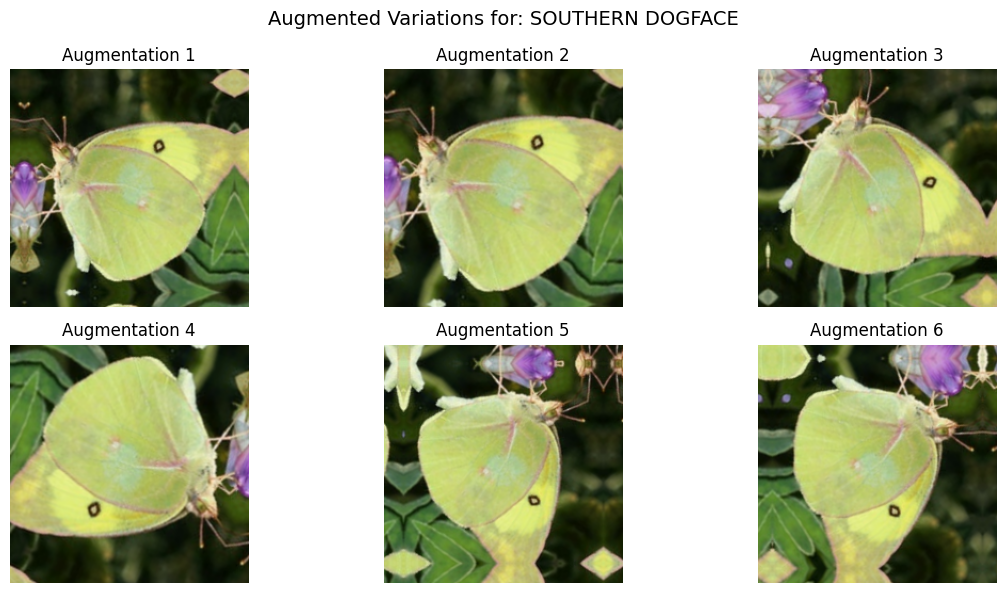

In [14]:
import numpy as np

# Load a sample image
sample_row = train_matched_df.iloc[0]
img = Image.open(sample_row['image_path']).resize((224, 224))
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0) # Create a batch

# Generate augmented variations
plt.figure(figsize=(12, 6))
for i in range(6):
    augmented_image = data_augmentation(img_array)
    ax = plt.subplot(2, 3, i + 1)
    plt.imshow(augmented_image[0].numpy().astype("uint8"))
    plt.title(f"Augmentation {i+1}")
    plt.axis("off")

plt.suptitle(f"Augmented Variations for: {sample_row['label']}", fontsize=14)
plt.tight_layout()
plt.show()

### Step: Model Development
We will construct a sequential CNN architecture utilizing our pre-defined image augmentation pipeline. First, let's identify the total number of target classes (butterfly species).

In [15]:
num_classes = train_matched_df['label'].nunique()
print(f"Number of target classes (butterfly species): {num_classes}")

Number of target classes (butterfly species): 75


Now, we define our Keras CNN model architecture, including input rescaling and convolutional blocks.

In [16]:
from tensorflow.keras import models, layers

# Define target image dimensions
IMG_HEIGHT = 224
IMG_WIDTH = 224
CHANNELS = 3

def build_model(num_classes):
    model = models.Sequential([
        # 1. Input Layer
        layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS)),

        # 2. Augmentation Pipeline
        data_augmentation,

        # 3. Rescaling layer to normalize pixel values to [0, 1]
        layers.Rescaling(1./255),

        # 4. Feature Extraction Blocks
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # 5. Classifier Head
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])

    return model

# Build and compile model
model = build_model(num_classes)
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display model summary
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    22,151,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 75)             │        19,275 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,263,947 (84.93 MB)

 Trainable params: 22,263,947 (84.93 MB)

 Non-trainable params: 0 (0.00 B)

### Step: Data Pipeline and Splitting
Before training our CNN model, we need to prepare our training and validation datasets. We will:
1. Encode the target butterfly classes (`label`) into integer values.
2. Split the training data into 80% training and 20% validation subsets.
3. Create efficient `tf.data.Dataset` pipelines that stream and preprocess images on demand.

In [17]:
from sklearn.model_selection import train_test_split
import tensorflow as tf

# 1. Map labels to integers
unique_labels = sorted(train_matched_df['label'].unique())
label_to_index = {label: idx for idx, label in enumerate(unique_labels)}
index_to_label = {idx: label for label, idx in label_to_index.items()}

train_matched_df['label_idx'] = train_matched_df['label'].map(label_to_index)

# 2. Perform train/validation split (80/20)
train_split_df, val_split_df = train_test_split(
    train_matched_df,
    test_size=0.2,
    random_state=42,
    stratify=train_matched_df['label_idx']
)

print(f"Training instances: {len(train_split_df)}")
print(f"Validation instances: {len(val_split_df)}")

Training instances: 5199
Validation instances: 1300


/tmp/ipykernel_631/2439013982.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_matched_df['label_idx'] = train_matched_df['label'].map(label_to_index)


In [18]:
# 3. Define tf.data preprocessing and load function
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_and_preprocess_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

# Create Training Dataset
train_ds = tf.data.Dataset.from_tensor_slices((
    train_split_df['image_path'].values,
    train_split_df['label_idx'].values
))
train_ds = train_ds.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.shuffle(buffer_size=1000).batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)

# Create Validation Dataset
val_ds = tf.data.Dataset.from_tensor_slices((
    val_split_df['image_path'].values,
    val_split_df['label_idx'].values
))
val_ds = val_ds.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)

print("Datasets successfully initialized and optimized with tf.data!")

Datasets successfully initialized and optimized with tf.data!


### Step: Model Training
Now we will train our CNN model using the built-in Keras `.fit()` method. We'll run it for 10 epochs as a starting benchmark to observe the training and validation performance.

In [19]:
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 439s 3s/step - accuracy: 0.0371 - loss: 4.1859 - val_accuracy: 0.1023 - val_loss: 3.6828
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 410s 3s/step - accuracy: 0.1273 - loss: 3.5192 - val_accuracy: 0.2008 - val_loss: 3.1411
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 432s 2s/step - accuracy: 0.2108 - loss: 2.9759 - val_accuracy: 0.3146 - val_loss: 2.5971
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 413s 3s/step - accuracy: 0.2976 - loss: 2.5947 - val_accuracy: 0.3708 - val_loss: 2.3032
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 395s 2s/step - accuracy: 0.3435 - loss: 2.3614 - val_accuracy: 0.4792 - val_loss: 1.9320
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 455s 2s/step - accuracy: 0.3797 - loss: 2.2109 - val_accuracy: 0.4715 - val_loss: 1.8383
Epoch 7/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 449s 3s/step - accuracy: 0.4287 - loss: 2.0528 - val_accuracy: 0.4792 - val_loss: 1.8357
Epoch 8/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 412s 3s/step - accuracy: 0.4414 - loss: 1.9594 - val_accu

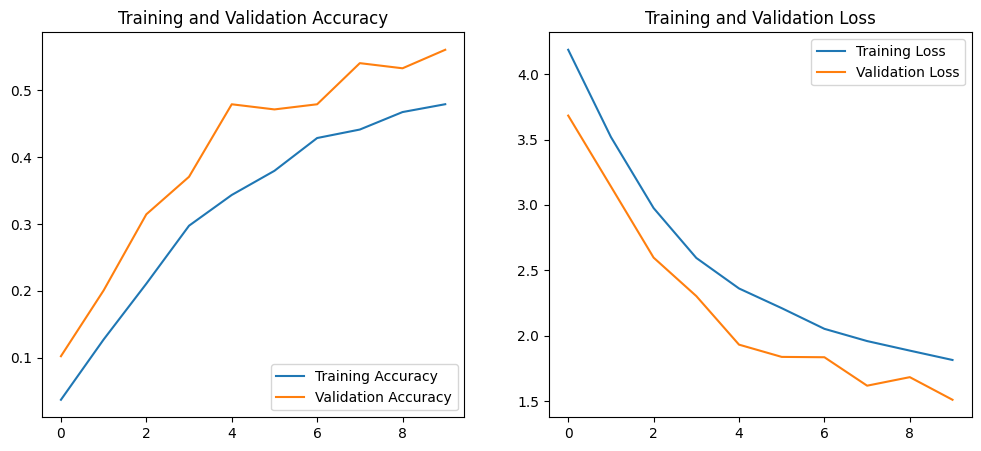

In [20]:
# Visualize loss and accuracy progression during training
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

### Step: Model Evaluation & Predictions
Since our official test dataset (`test_matched_df`) doesn't contain ground truth labels, we will evaluate the model's classification metrics using our validation dataset (`val_ds`). We will:
1. Extract true labels and model predictions.
2. Compute and display the **Classification Report** (Precision, Recall, F1-score).
3. Plot the **Confusion Matrix** for the 75 classes.
4. Save the trained model to a file.

In [21]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Retrieve all true labels and predictions from validation set
y_true = []
y_pred = []

print("Generating predictions for the validation dataset...")
for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# 2. Print Classification Report
print("\n=== Classification Report ===\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=unique_labels,
    labels=range(len(unique_labels)),
    zero_division=0
))

Generating predictions for the validation dataset...

=== Classification Report ===

                           precision    recall  f1-score   support

                   ADONIS       1.00      0.83      0.91        18
AFRICAN GIANT SWALLOWTAIL       0.57      0.80      0.67        15
           AMERICAN SNOOT       0.64      0.47      0.54        15
                    AN 88       0.88      0.88      0.88        17
                  APPOLLO       0.43      0.67      0.52        18
                    ATALA       0.40      0.95      0.57        20
 BANDED ORANGE HELICONIAN       0.72      0.65      0.68        20
           BANDED PEACOCK       0.65      0.76      0.70        17
            BECKERS WHITE       0.40      0.38      0.39        16
         BLACK HAIRSTREAK       0.65      0.65      0.65        17
              BLUE MORPHO       0.75      0.40      0.52        15
        BLUE SPOTTED CROW       0.41      0.41      0.41        17
           BROWN SIPROETA       0.92      0

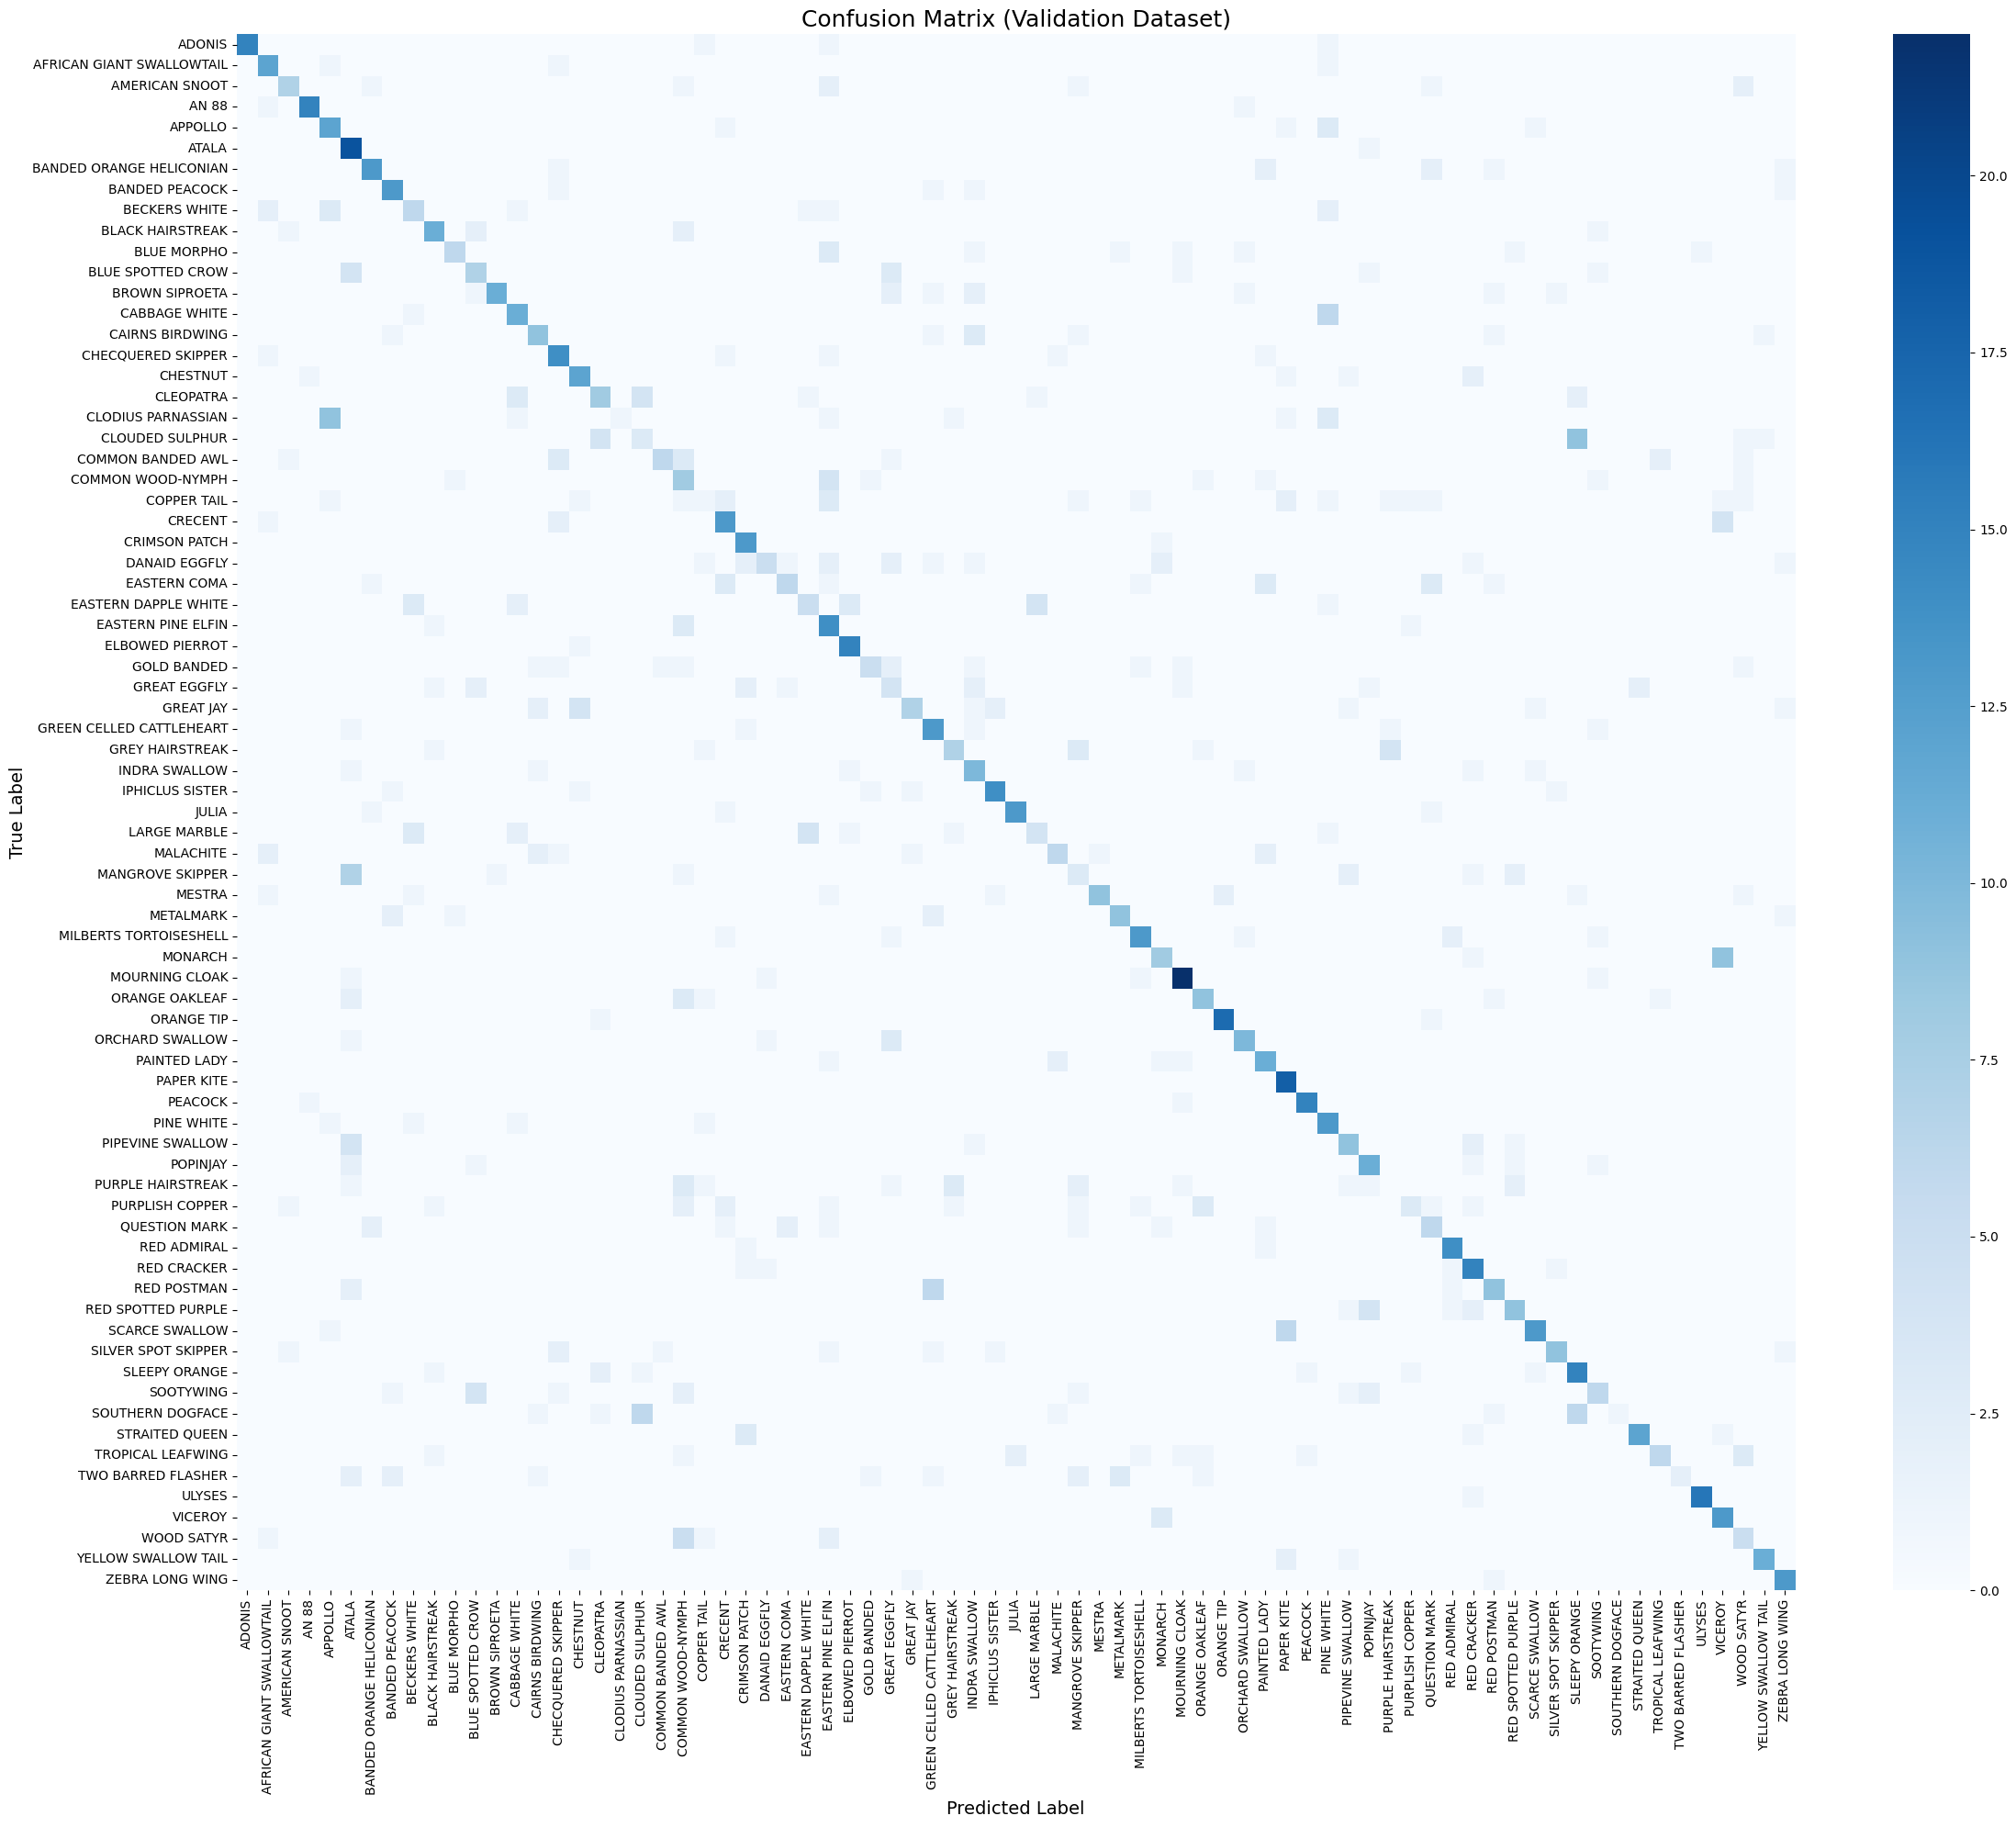

In [22]:
# 3. Compute and Plot the Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=range(len(unique_labels)))

plt.figure(figsize=(24, 20))
sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=unique_labels,
    yticklabels=unique_labels
)
plt.title("Confusion Matrix (Validation Dataset)", fontsize=18)
plt.xlabel("Predicted Label", fontsize=14)
plt.ylabel("True Label", fontsize=14)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Step: Save the Model
We will save our trained TensorFlow model to a file named `butterfly_cnn_model.keras` so that it can be loaded later for inference or deployment.

In [23]:
# Save the model in native Keras format
model_save_path = 'butterfly_cnn_model.keras'
model.save(model_save_path)
print(f"Model successfully saved to '{model_save_path}'!")

Model successfully saved to 'butterfly_cnn_model.keras'!


### Step: Download Saved Model to Local Machine
Because this environment runs on a remote server, we must download the saved `.keras` model file through the browser to save it locally on your computer.

In [24]:
from google.colab import files

# Trigger a browser download of the saved model file
files.download('butterfly_cnn_model.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Step: Single Image Inference Helper
Below, we define a helper function to perform classification on any single image path. We will load the saved `.keras` model, preprocess the image, run inference, and map the numeric output back to its human-readable species name.

In [25]:
import numpy as np
import tensorflow as tf
from PIL import Image
import matplotlib.pyplot as plt

def predict_single_image(image_path, model_path='butterfly_cnn_model.keras'):
    # 1. Load the saved Keras model
    loaded_model = tf.keras.models.load_model(model_path)

    # 2. Load and preprocess the image
    img = Image.open(image_path)
    img_resized = img.resize((224, 224))

    # Convert image to numpy array and add a batch dimension
    img_array = tf.keras.utils.img_to_array(img_resized)
    img_array = tf.expand_dims(img_array, 0)  # Shape becomes (1, 224, 224, 3)

    # 3. Perform prediction
    predictions = loaded_model.predict(img_array)
    predicted_class_idx = np.argmax(predictions[0])
    confidence = predictions[0][predicted_class_idx]

    # Decode the class label using index_to_label
    predicted_label = index_to_label[predicted_class_idx]

    # 4. Visualize the result
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Predicted Species: {predicted_label}\nConfidence: {confidence:.2%}", fontsize=12)
    plt.axis('off')
    plt.show()

    return predicted_label, confidence

Let's test this inference helper function on a sample image from our test set!

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step


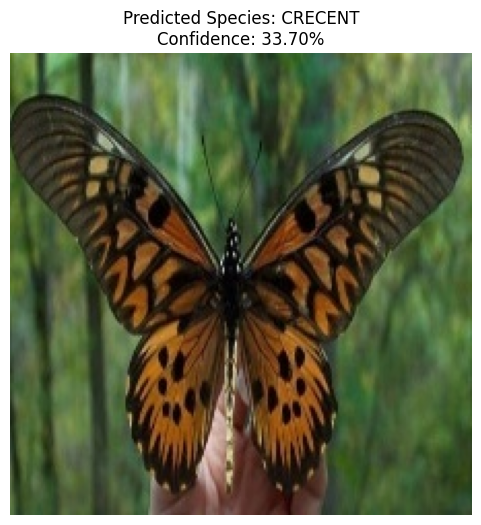

In [26]:
# Grab a sample from the test dataset to test our inference function
sample_test_path = test_matched_df.iloc[10]['image_path']

predicted_label, confidence = predict_single_image(sample_test_path)

### Step: Upload a Local Image and Run Inference
Run the cell below to upload an image directly from your local computer (e.g. `jpg`, `png`, or `jpeg`). The script will automatically detect the uploaded file and run our prediction helper on it.

Saving butterfly 1.jfif to butterfly 1.jfif

Successfully uploaded: butterfly 1.jfif
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step


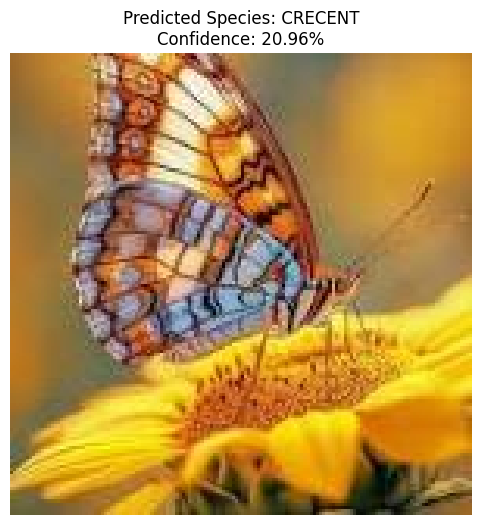

In [27]:
from google.colab import files
import os

# 1. Trigger the file upload dialog
uploaded = files.upload()

# 2. Extract the file path of the uploaded image
if uploaded:
    uploaded_filename = list(uploaded.keys())[0]
    print(f"\nSuccessfully uploaded: {uploaded_filename}")

    # 3. Run our prediction helper function
    predicted_label, confidence = predict_single_image(uploaded_filename)
else:
    print("No file uploaded.")

### 📄 Local Python Inference Script (`predict.py`)

Below is the complete, self-contained Python code you should save locally as `predict.py` alongside your `butterfly_cnn_model.keras` file.

In [ ]:
import os
import numpy as np
import tensorflow as tf
from PIL import Image
import matplotlib.pyplot as plt

# 1. 75 target butterfly classes in alphabetical order
CLASS_NAMES = [
    'ADONIS', 'AFRICAN GIANT SWALLOWTAIL', 'AMERICAN SNOOT', 'AN 88', 'APPOLLO',
    'ATALA', 'BANDED ORANGE HELICONIAN', 'BANDED PEACOCK', 'BECKERS WHITE',
    'BLACK HAIRSTREAK', 'BLUE MORPHO', 'BLUE SPOTTED CROW', 'BROWN SIPROETA',
    'CABBAGE WHITE', 'CAIRNS BIRDWING', 'CHECQUERED SKIPPER', 'CHESTNUT',
    'CLEOPATRA', 'CLODIUS PARNASSIAN', 'CLOUDED SULPHUR', 'COMMON BANDED AWL',
    'COMMON WOOD-NYMPH', 'COPPER TAIL', 'CRECENT', 'CRIMSON PATCH', 'DANAID EGGFLY',
    'EASTERN COMA', 'EASTERN DAPPLE WHITE', 'EASTERN PINE ELFIN', 'ELBOWED PIERROT',
    'GOLD BANDED', 'GREAT EGGFLY', 'GREAT JAY', 'GREEN CELLED CATTLEHEART',
    'GREY HAIRSTREAK', 'INDRA SWALLOW', 'IPHICLUS SISTER', 'JULIA', 'LARGE MARBLE',
    'MALACHITE', 'MANGROVE SKIPPER', 'MESTRA', 'METALMARK', 'MILBERTS TORTOISESHELL',
    'MONARCH', 'MOURNING CLOAK', 'ORANGE OAKLEAF', 'ORANGE TIP', 'ORCHARD SWALLOW',
    'PAINTED LADY', 'PAPER KITE', 'PEACOCK', 'PINE WHITE', 'PIPEVINE SWALLOW',
    'POPINJAY', 'PURPLE HAIRSTREAK', 'PURPLISH COPPER', 'QUESTION MARK',
    'RED ADMIRAL', 'RED CRACKER', 'RED POSTMAN', 'RED SPOTTED PURPLE',
    'SCARCE SWALLOW', 'SILVER SPOT SKIPPER', 'SLEEPY ORANGE', 'SOOTYWING',
    'SOUTHERN DOGFACE', 'STRAITED QUEEN', 'TROPICAL LEAFWING', 'TWO BARRED FLASHER',
    'ULYSES', 'VICEROY', 'WOOD SATYR', 'YELLOW SWALLOW TAIL', 'ZEBRA LONG WING'
]

def predict_local_image(image_path, model_path='butterfly_cnn_model.keras'):
    # Verify files exist
    if not os.path.exists(model_path):
        raise FileNotFoundError(f"Could not find model file at '{model_path}'. Check your directory path!")
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Could not find image file at '{image_path}'. Check your filename!")

    # Load saved model
    print("Loading saved Keras model...")
    model = tf.keras.models.load_model(model_path)

    # Load and preprocess image to match (224, 224, 3)
    print(f"Preprocessing image: {image_path}...")
    img = Image.open(image_path)
    img_resized = img.resize((224, 224))

    # Convert to array and expand dimensions to create batch shape (1, 224, 224, 3)
    img_array = tf.keras.utils.img_to_array(img_resized)
    img_array = tf.expand_dims(img_array, 0)

    # Run prediction
    print("Running model inference...")
    predictions = model.predict(img_array)
    predicted_class_idx = np.argmax(predictions[0])
    confidence = predictions[0][predicted_class_idx]
    predicted_label = CLASS_NAMES[predicted_class_idx]

    # Print prediction results
    print("\n=== Prediction Result ===")
    print(f"Species: {predicted_label}")
    print(f"Confidence: {confidence:.2%}")

    # Render image with matplotlib
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Predicted Species: {predicted_label}\nConfidence: {confidence:.2%}")
    plt.axis('off')
    plt.show()

if __name__ == '__main__':
    # Ask user dynamically for image file name in terminal
    img_name = input("Enter the filename of your butterfly image (e.g., test.jpg): ").strip()
    try:
        predict_local_image(img_name)
    except Exception as e:
        print(f"Error: {e}")